# Question 1

by Anna Havner

***

**Does a mother’s pre-existing physiological or psychological burden compound the negative impacts of pregnancy-related complications on newborn health?**

My overall plan is to examine the Perceived Vulnerability to Disease dataset to explore how extra physiological stress has adverse effects in pregnancy-related complications. I plan to use the columns noting prenatal physiological health in the individuals (Allergies, Asthma, Endometriosis, Diabetes, Hypertension, Thyroid problems, Hormonal Problems) to make a physiological health burden index, and use the columns noting prenatal psychological health (Perceived Stress Scale, Germ Aversion Sum, Infectability sum) to make a psychological health burden index. I will look into individual effects in newborn health (APGAR score, birth weight) but I will create an overall newborn health index to use for general comparisons.. I will then look at pregnancy-related complications (Pregnancy diabetes 1Y, Thyroid gland problems 1Y, Hypertension 1Y) with newborn health outcomes and compare differences among subsets of individuals with better or worse prenatal health.

Expected Outcomes: I expect to see that individuals with worse prenatal health, both physiological and psychological, have compounded adverse health effects during pregnancy on newborn health outcomes. One possible limitation is in examining psychological health, I don't have very much data on this. If I could find a similar dataset that also included anxiety, depression, etc. it could be better to examine the psychological aspect with.

*Step 1: Load data & clean empty columns*

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pvd = pd.read_excel('data/pvdstudy.xlsx')

In [4]:
pvd_cleaned = pvd.dropna(axis=1, how='any')
pvd_cleaned.columns.tolist()

['L.P.',
 'Participant code',
 'Stress1',
 'Stress2',
 'Stress3',
 'Stress4',
 'Stress5',
 'Stress6',
 'Stress7',
 'Stress8',
 'Stress9',
 'Stress10',
 'SUM (0-40)',
 'PVD1',
 'PVD2',
 'PVD3',
 'PVD4',
 'PVD5',
 'PVD6',
 'PVD7',
 'PVD8',
 'PVD9',
 'PVD10',
 'PVD11',
 'PVD12',
 'PVD13',
 'PVD14',
 'PVD15',
 'Infectability SUM',
 'Germ SUM',
 'Total SUM',
 'Pregnancy week',
 'Age',
 'Weight before pregnancy',
 'Current weight',
 'Height',
 'Partner weight',
 'Partner age',
 'Partner height',
 'Asthma',
 'Allergies',
 'Epilepsy',
 'Heart condition',
 'Diabetes',
 'Thyroid problems',
 'Hypertension',
 'Coronary heart disease',
 'Anaemia',
 'Endometriosis',
 'Other diseases',
 'Hormonal problems',
 'Education',
 'Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)',
 'SES self-assessment (1very poor to 7very good)',
 'Relationship status (1single, 2cohabiting, 3married)',
 'Relationship with a biologic

*Step 2: Select columns to be used*

* Physiological burden variables: Allergies, Asthma, Endometriosis, Diabetes, Hypertension, Thyroid problems, Hormonal Problems
* Psychological burden variables: Perceived Stress Scale, Germ Aversion Sum, Infectability sum
* Pregnancy-related health issues: Pregnancy diabetes 1Y, Thyroid gland problems 1Y, Hypertension 1Y
* Newborn health: APGAR mean, Problems during childbirth, Birth Weight



*Step 3: clean the data and rename column names (will work on this later)*
phyburcols = 

*Step 4: first pass at visualization, just using one variable for now.*

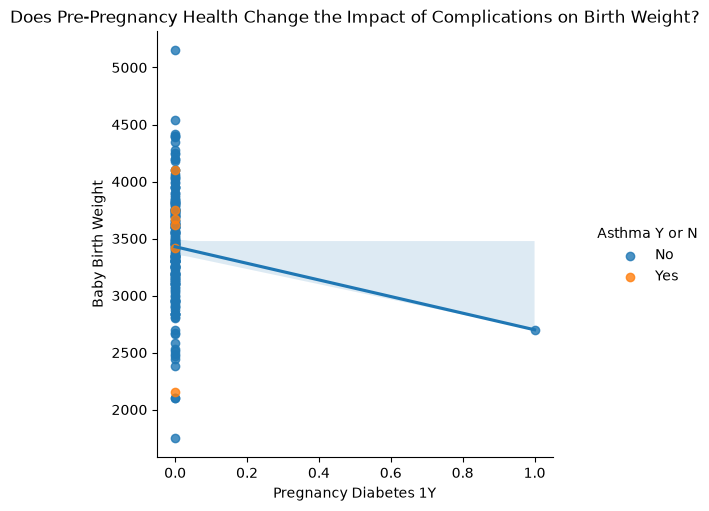

In [5]:
pvd = pd.read_excel('data/pvdstudy.xlsx')
pvd_cleaned = pvd.dropna(axis=1, how='any')
pvd_cleaned.columns.tolist()

phys = 'Asthma'
x = 'Pregnancy diabetes 1y'
y = 'Birth weight'

xtraclean = pvd_cleaned[[phys, x, y]].dropna().copy()
xtraclean[x] = xtraclean[x].apply(lambda val: 1 if 'cukrzyca' in str(val).lower() else 0)
xtraclean[phys] = pd.to_numeric(xtraclean[phys], errors='coerce')
xtraclean[y] = pd.to_numeric(xtraclean[y], errors='coerce')
xtraclean = xtraclean.dropna()

xtraclean['Asthma Y or N'] = xtraclean[phys].map({1: 'Yes', 0: 'No'})

sns.lmplot(
    data=xtraclean,
    x=x,
    y=y,
    hue='Asthma Y or N')

plt.title('Does Pre-Pregnancy Health Change the Impact of Complications on Birth Weight?')
plt.xlabel('Pregnancy Diabetes 1Y')
plt.ylabel('Baby Birth Weight')

plt.show()

**Limitations:** One possible limitation is in examining psychological health, I don't have very much data on this. If I could find a similar dataset that also included anxiety, depression, etc. it could be better to examine the psychological aspect with. In making this first look, I have also discovered that a big limitation is inconsistency of data within my dataset. It is very unlikely that only one individual in this study had asthma, yet in the plot above, only one datapoint shows Yes to having had asthma.